# Toward a full SPH implementation in Peano


We let particles interact via short-range gravity, i.e., we neglect long-range contributions. This is because the interaction is calculated based on the local and active sets -- see docs.

In [1]:
import os

import peano4
import peano4.dastgen2
import peano4.toolbox
import peano4.toolbox.particles
import dastgen2

DaStGen 2 (C) www.peano-framework.org
Peano 4 (C) www.peano-framework.org


In [2]:
# If we want to start a project from scratch, we may want to remove some of the generated code
!make clean; rm -r actions/ vertexdata/ repositories/ globaldata/ celldata/ observers/ 

project = peano4.Project( ["examples", "particles"], "sph-peano", "." )

rm -f celldata/ParticleSetCellStatistics.o vertexdata/ParticleSet.o globaldata/Particle.o repositories/DataRepository.o ./observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.o ./observers/CreateGrid.o ./observers/Init2peano4_toolbox_particles_UpdateParticleGridAssociation0.o ./observers/Init2peano4_toolbox_particles_InsertRandomParticlesIntoUnrefinedCells1.o ./observers/Init2peano4_toolbox_particles_ParticleTreeAnalysis2.o ./observers/Init.o ./actions/CalcDensities.o ./observers/CalcDensities2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleParticleInteraction2.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleAMR3.o ./observers/CalcDensities2peano4_toolbox_particles_ParticleTreeAnalysis4.o ./observers/CalcDensities.o ./actions/CalcDensitiesAndSmoothingLengthNR.o ./observers/CalcDensitiesAndSmoothingLengthNR2peano4_toolbox_particles_UpdateParticleGridAssociation1.o ./observers/CalcDensitiesAndSmoothingLen

## Prepare code

Peano's API does not know which settings to use on the present system. To make it copy/clone the settings identified by ./configure, we ask it to parse the generated configuration scripts. 

In [3]:
build_mode = peano4.output.CompileMode.Asserts
#build_mode = peano4.output.CompileMode.Release
project.output.makefile.parse_configure_script_outcome( "../../.." )
project.output.makefile.set_mode( build_mode )

parse configure outcome ../../../config.log to extract configure settings
found the configure call info   $ ./configure --with-mpi=mpicxx --with-multithreading=omp CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops CC=gcc CXX=g++ FC=gfortran --enable-loadbalancing --enable-exahype --enable-particles --enable-blockstructured

parse configure outcome ../../../src/Makefile to extract compile settings
add CXX=mpicxx
add CXXFLAGS=--std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops
add CXXFLAGS_PEANO_2D_ASSERTS=-DDimensions=2 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_2D_DEBUG=-DDimensions=2 -DPeanoDebug=4 -g3 -O0
add CXXFLAGS_PEANO_2D_RELEASE=-DDimensions=2 -DPeanoDebug=0
add CXXFLAGS_PEANO_2D_STATS=-DDimensions=2 -DPeanoDebug=0 -DTrackStatistics
add CXXFLAGS_PEANO_2D_TRACE=-DDimensions=2 -DPeanoDebug=1 -g3
add CXXFLAGS_PEANO_3D_ASSERTS=-DDimensions=3 -DPeanoDebug=2 -g3 -O0
add CXXFLAGS_PEANO_3D_DEBUG=-DDimensions=3 -DPeanoDebug=4 -g3

## Model the particle

We create the particle through the toolbox. A particle by definition has a position, so we just need to add everything else for SPH:
- Velocity array
- Acceleration array
- Mass
- Density
- Pressure
- Internal Energy (U)
- Time derivative of internal energy (U')
- Kernel smoothing length

We add a marker to indicate the next calculation step required for a particle so we don't perform the same step on a particle twice in a row.

We also add an array to store the new position of a particle after a timestep is completed. We will use this to move the particle at the start of the subsequent timestep.

In [4]:
particle = peano4.toolbox.particles.Particle("Particle")

# Define properties
v_attr = peano4.dastgen2.Peano4DoubleArray("v","Dimensions")
mass_attr    = dastgen2.attributes.Double("mass")
density_attr = dastgen2.attributes.Double("density")
pressure_attr= dastgen2.attributes.Double("pressure")
u_attr       = dastgen2.attributes.Double("u")
#uDash_attr   = dastgen2.attributes.Double("uDash")
smoothL_attr = dastgen2.attributes.Double("smoothingLength")

# For variable smoothing length
has_converged_attr= dastgen2.attributes.Boolean("hasConverged")
smoothL_prev_attr = dastgen2.attributes.Double("smoothingLengthPrevious")
Omega_attr        = dastgen2.attributes.Double("Omega")
rhoDot_attr       = dastgen2.attributes.Double("rhoDot")
DebugNeg_attr     = dastgen2.attributes.Double("DebugNeg")

# Step attributes (check)
#step_attr    = dastgen2.attributes.Enumeration("step", ["calcDensity", "calcAccel", "move"]) # Check!
#step_attr    = dastgen2.attributes.Enumeration("step", ["calcDensity","calcInternalEnergy" ,"Move"]) # Check!
#step_attr    = dastgen2.attributes.Enumeration("step", ["CalcDensitiesAndSmoothingLengthNR","calcInternalEnergy" ,"Move"]) # Check!

#newX_attr    = peano4.dastgen2.Peano4DoubleArray("newX", "Dimensions") # updated copy of X

# Add particle properties
particle.data.add_attribute(v_attr)
particle.data.add_attribute(mass_attr)
particle.data.add_attribute(density_attr)
particle.data.add_attribute(pressure_attr)
particle.data.add_attribute(u_attr)
#particle.data.add_attribute(uDash_attr)
particle.data.add_attribute(smoothL_attr)
# For variable smoothing length
particle.data.add_attribute(has_converged_attr)
particle.data.add_attribute(smoothL_prev_attr)
particle.data.add_attribute(Omega_attr)
particle.data.add_attribute(rhoDot_attr)
particle.data.add_attribute(DebugNeg_attr)

# Check these
#particle.data.add_attribute(step_attr)
#particle.data.add_attribute(newX_attr)

particles = peano4.toolbox.particles.ParticleSet(particle)

This particle has to be added to the project. This way the project knows that we are working with this guy. We associate the particle with the vertices, as we work with the pidt (particle in dual tree) algorithm. 

In [5]:
project.datamodel.add_global_object(particle)
project.datamodel.add_vertex       (particles)

## Export global SPH constants

There are plenty of constant simulation paramaters to specify for our SPH simulation - we do that here. 

In [6]:
Dimensions = 2
project.output.makefile.set_dimension(Dimensions)

In [7]:
from numpy import pi

# Estimate free parameter for smoothing length based on how many average ngbs we want to use
N_ngbs_mean = 10.0 # 57.9

if(Dimensions==2):
    SMOOTH_L_FAC = str( (1.   /pi*N_ngbs_mean)**(1./2.)/2. ) 
    CUBIC_SPLINE_SIGMA = str(10/(7*pi))
    
elif(Dimensions==3):
    SMOOTH_L_FAC = str( (3./4./pi*N_ngbs_mean)**(1./3.)/2. ) 
    CUBIC_SPLINE_SIGMA = str(1/pi)

print(SMOOTH_L_FAC, CUBIC_SPLINE_SIGMA)

# SPH constants
GAMMA = str(5/3)
#DYNAMIC_VISCOSITY     = "0.00001"
#TARGET_PARTICLE_SIZE  = "0.01"
#ENERGY_SPIKE = "0.1"
#SPIKE_RADIUS = "0.08"
#REST_DENSITY = "1"
#INITIAL_H = "0.02"

project.constants.export_const_with_type("GAMMA", GAMMA, "double")
project.constants.export_const_with_type("SMOOTH_L_FAC"      , SMOOTH_L_FAC      , "double")
project.constants.export_const_with_type("CUBIC_SPLINE_SIGMA", CUBIC_SPLINE_SIGMA, "double")
#project.constants.export_const_with_type("DYNAMIC_VISCOSITY", DYNAMIC_VISCOSITY, "double")
#project.constants.export_const_with_type("TARGET_PARTICLE_SIZE", TARGET_PARTICLE_SIZE, "double")
#project.constants.export_const_with_type("ENERGY_SPIKE", ENERGY_SPIKE, "double")
#project.constants.export_const_with_type("SPIKE_RADIUS", SPIKE_RADIUS, "double")
#project.constants.export_const_with_type("REST_DENSITY", REST_DENSITY, "double")
#project.constants.export_const_with_type("INITIAL_H", INITIAL_H, "double")

0.8920620580763856 0.4547284088339867


## Model the setup phases

The setup remains almost unchanged. I give all particles a biased random initial velocity. This will introduce an adaptive mesh, as particles will cluster in the bottom left part of the 2d domain.

In [8]:
mesh_size = 0.2

particle_tree_analysis = peano4.toolbox.particles.ParticleTreeAnalysis(particles)
project.datamodel.add_cell(particle_tree_analysis.cell_marker)   # read docu of ParticleTreeAnalysis

create_grid = peano4.solversteps.Step( name="CreateGrid", add_user_defined_actions=False )
create_grid.add_action_set( peano4.toolbox.CreateRegularGrid(mesh_size) )
create_grid.use_vertex(particles)
create_grid.use_cell(particle_tree_analysis.cell_marker)
project.solversteps.add_step(create_grid)

## Initial conditions for particles

In [9]:
initialisation_snippet = """
 
 particle->setCutOffRadius(0.05);
// particle->setCutOffRadius(1E-2);

 // We will set random velocities for (v_x, v_y)
 particle->setV( 0, 1E0*(0.5 -((double) rand() / (RAND_MAX))) );
 particle->setV( 1, 1E0*(0.5 -((double) rand() / (RAND_MAX))) );
 
 // For SPH, we also want to initialise a few more variables:
 particle->setMass    (1E-2);       
 particle->setDensity (1.0);        
 particle->setU       (1.E-2);
 particle->setPressure(1.0);
 particle->setSmoothingLength(SMOOTH_L_FAC * std::pow(particle->getMass()/particle->getDensity(), 1.0/Dimensions) );
 particle->setSmoothingLengthPrevious(1E-1);
 particle->setOmega (0.0);        
 particle->setRhoDot(0.0);        
 particle->setDebugNeg(-1.0);        

"""

init_setup = peano4.solversteps.Step( name="Init", add_user_defined_actions=False )
init_setup.use_vertex(particles)
init_setup.use_cell(particle_tree_analysis.cell_marker)
init_setup.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
init_setup.add_action_set( peano4.toolbox.particles.InsertRandomParticlesIntoUnrefinedCells(
  particle_set=particles,
  average_distance_between_particles=mesh_size/10,
#  average_distance_between_particles=mesh_size/20,
  initialisation_call=initialisation_snippet,
  noise=True,
  additional_includes=""" 
    #include "Constants.h" 
    """ ))
init_setup.add_action_set( particle_tree_analysis )
project.solversteps.add_step(init_setup)

## Particle behaviour

We stick to exactly the same particle behaviour from a code point of view. However, we use a pre-manufactured toolbox  into which we inject the actual code. The important fact here is that we now do not simply rely on the particles of the adjacent vertices of a cell. Instead, we work with active and local particle sets.

ls: cannot access '../../python/peano4/toolbox/particles': No such file or directory


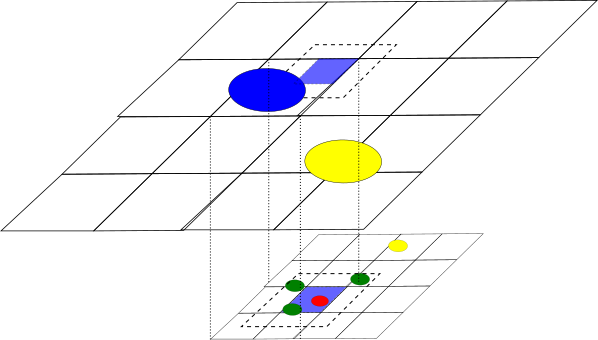

In [10]:
from IPython.display import Image
!ls ../../python/peano4/toolbox/particles
Image("../../../python/peano4/toolbox/particles/dependency_sets.png")

To understand what the individual particles in the sketch above are supposed to mean and how they are maintained and exposed to the user, please consult the documentation of the ParticleParticleInteraction class in the Python toolbox directory. It contains a lot explanations.

## Write the actual particle movement (the move step below)

We will implement the actual particle movement ourselves. For this, we have asked Move to be an action set with manual user code, and indeed we get a Move class in the actions subdirectory once we have triggered the build process. This is, same as main, an empty blueprint. We can alter it, and Peano won't overwrite it anymore after that. If we delete it, the API will regenerate it however. The current example has already a pre-prepared Move, so it won't be empty, but you might want to delete it and regenerate it to see what you get in the first place.

Here's what I changed in the Move class: Move is a standard class which defines an action set: There's a fixed number of callbacks that are invoked by Peano, and we can use these to inject behaviour. I only alter (or plug into) three actions: 

### First access to vertex

Particles are associated to vertices. So when I hit a vertex the first time, I also hit the particles associated with it for the first time. I run over them, and set their status to NotMovedYet:

     for (auto& p: fineGridVertexParticleSet) {
       p->setMoveState( globaldata::Particle::MoveState::NotMovedYet );
     }

### Hit cell

When I hit a cell, I actually evaluate the "forces" and alter the particles' velocities. I do this only for the particles that reside within the cell, as I know that a neighbouring cell will either be hit after or before the current one. If I modified all particles associated with the 2^d vertices of a cell, I'd modify particles multiple times. 

Please note that I only change the particles' attributes. I do not change their position. That means, the logical topology of all data, i.e. how they are assigned to vertices remains valid and intact. This means that we don't care how Peano runs through the cells. All data remains valid.

Please see touchCellFirstTime() for details.


### Last access to vertex

When I hit a vertex for the last time, I know that all 2^d adjacent cells have been "visited". Therefore, I can now finally update the vertex position. The vertex won't be used by neighbouring cells anymore and we are fine. Again, I do this only for particles that haven't moved yet. Otherwise we might move a particle, it ends up around another vertex that we haven't processed yet and then it is moved again.

    const double timeStepSize = 0.0001;
    for (auto& p: fineGridVertexParticleSet) {
      if (
        p->getMoveState()!=globaldata::Particle::MoveState::Moved
        and
        p->getParallelState()==globaldata::Particle::ParallelState::Local
      ) {
        p->setX( p->getX() + timeStepSize * p->getV() );
        for (int d=0; d<Dimensions; d++) {
          if ( p->getX()(d)<0.0 ) {
            p->setV(d, std::abs(p->getV()(d)));
          }
          if ( p->getX()(d)>1.0 ) {
            p->setV(d, -std::abs(p->getV()(d)));
          }
        }
      }
      p->setMoveState( globaldata::Particle::MoveState::Moved );
    }

You see, we also add reflecting boundary conditions.

## Calculate densities at particles (density loop)

For each particle, we calculate the density at its position based on the positions and masses of the particles in its neighbourhood via

\begin{align}
\rho_a& = \sum_b m_b W(|{\bf r}_a - {\bf r}_b|, h_a)
\end{align}
Once the loop is done and density has been calculated, we can evaluate the fluid pressure at the particle's position using the Equation of State:

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}
Notice that, if $u$ has evolved, we should evaluate $P$ later.

In [11]:
calc_densities = peano4.solversteps.Step( "CalcDensities" )
calc_densities.use_vertex(particles)
calc_densities.use_cell(particle_tree_analysis.cell_marker)
calc_densities.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """
// The used action set does the run over the local set and the active set. So we
// simply have to feed in the particle-particle interaction potential.
 
  tarch::la::Vector<Dimensions,double> distVec = localParticle->getX() - activeParticle->getX();
  const double dist = tarch::la::norm2( localParticle->getX() - activeParticle->getX() );

  const double h = localParticle->getSmoothingLength();
  if ( dist < localParticle->getCutOffRadius() ) {
    const double q = dist / h;
    
    // Density calculation
    // Default SPH kernel (cubic spline)
    double W = CUBIC_SPLINE_SIGMA / (h*h);   // 2D kernel normalization
    if(Dimensions==3) W /= h;                // 3D kernel normalization
    
    if (q >= 2) {
      W *= 0;
    } else if (q >= 1) {
      W *= (0.25 * (2 - q)*(2 - q)*(2 - q));
    } else {
      W *= (1 - 1.5*q*q*(1 - q/2));
    }

    double densityNgbs = activeParticle->getMass() * W;
    localParticle->setDensity( localParticle-> getDensity() + densityNgbs );
  }
"""

touch_particle_last_time_compute_kernel = """

  assertion2( not localParticle->getDensity() < 1E-8, localParticle->toString(), localParticle->getDensity() );

  // Here we update the pressure with the EoS since density is done by now.
  double eosPressure = localParticle->getDensity() * localParticle->getU() * (GAMMA - 1);
  localParticle->setPressure( (eosPressure < 0) ? 0 : eosPressure );
"""

touch_particle_first_time_compute_kernel = """
  // Default SPH kernel (cubic spline)
  const double h = localParticle->getSmoothingLength();
  
  double W = CUBIC_SPLINE_SIGMA / (h*h);   // 2D kernel normalization
  if(Dimensions==3) W /= h;                // 3D kernel normalization
  
  // we'll accumulate the data throughout mesh/particle traversal
  localParticle->setDensity (localParticle->getMass() * W );   // particle's own contribution
  localParticle->setPressure(0.0);  
"""

calc_densities.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes='#include "Constants.h" '
))
calc_densities.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
calc_densities.add_action_set( particle_tree_analysis )
project.solversteps.add_step(calc_densities)

## Density loop with variable smoothing length

In the case of variable smoothing length, $h\neq{\rm const.}$, we need to calculate this alongside with density in a self-consistent way. We proceed in two steps as follows:

1. We loop over neighbours ($b$) with the current value of $h$, to calculate the various sums:

\begin{align}
\rho_a& = \sum_b m_b W(|{\bf r}_a - {\bf r}_b|, h_a)\\
\Omega_a -1 &= - \frac{\partial h_a}{\partial \rho_a}\sum_b m_b\frac{\partial W_{ab}(h_a)}{\partial h_a} \qquad\qquad (\Omega_a=1 \quad \textrm{for constant $h$})\\
\frac{{\rm d}{\rho_a}}{{\rm d}t} &= \frac{1}{\Omega_a}\sum_b m_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)
\end{align}
The latter is later used to calculate the initial guess for the Newton-Raphson, which can reduce the number of required iterations.

2. Once the above have been calculated, we solve iteratively for $h$ using Newton-Raphson:

\begin{align}
\zeta(h_a)&\equiv m_a\left(\frac{\eta}{h_a}\right)^{3}-\sum_b m_b W_{ab}(h_a)=0\\
\textrm{Initial guess:} &\qquad\qquad h^{\rm ini}_a =h_a + \Delta t \frac{\partial h_a}{\partial\rho_a}\frac{d\rho_a}{dt}\\ 
\textrm{N-R iteration:}&\qquad\qquad h_{a,{\rm new}}=h_a - \frac{\zeta({h_a})}{\zeta'(h_a)} \qquad \textrm{where:}\qquad \zeta'(h_a)=-\frac{3\rho_a \Omega_a}{h_a}
\end{align}


Once $\rho$ (and $h$) has been calculated, we can evaluate the fluid pressure at the particle's position using the Equation of State:

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}
Notice that, if $u$ has evolved, we should evaluate $P$ later.

In [12]:
calc_densities_var_h = peano4.solversteps.Step( "CalcDensitiesAndSmoothingLengthNR" )
calc_densities_var_h.use_vertex(particles)
calc_densities_var_h.use_cell(particle_tree_analysis.cell_marker)
calc_densities_var_h.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )

particle_particle_compute_kernel = """
// The used action set does the run over the local set and the active set. So we
// simply have to feed in the particle-particle interaction.

// Here we calculate the density, Omega and drho/dt sums.
// These are later used in the Newton-Raphson iteration.
    
  tarch::la::Vector<Dimensions,double> distVec = localParticle->getX() - activeParticle->getX();
  const double dist = tarch::la::norm2( localParticle->getX() - activeParticle->getX() );
  
  const double h = localParticle->getSmoothingLength();
  const double cutoffR = 2*h;
  
  if ( tarch::la::greater( dist,0.0 ) ) {
    if ( dist < cutoffR ) {
  //  if ( dist < localParticle->getCutOffRadius() ) {
     
      const double q = dist / h;
      
      // Default SPH kernel (cubic spline)
      double W = CUBIC_SPLINE_SIGMA / (h*h);   // 2D kernel normalization
      if(Dimensions==3) W /= h;                // 3D kernel normalization      
      
      if (q >= 2) {
        W *= 0.0;
      } else if (q >= 1) {
        W *= (0.25 * (2 - q)*(2 - q)*(2 - q));
      } else {
        W *= (1 - 1.5*q*q*(1 - q/2));
      }
    
      double densityNgbs = activeParticle->getMass() * W;
      localParticle->setDensity( localParticle-> getDensity() + densityNgbs );
      
      // Calculation of dW/dh for Omega
      double dWdh = CUBIC_SPLINE_SIGMA / (h*h);   // 2D kernel normalization
      if(Dimensions==3) dWdh /= h;                // 3D kernel normalization
      
      if (q >= 2) {
        dWdh *= 0.0;
      } else if (q >= 1) {
        dWdh *= q* (-0.75 * ((2 - q)*(2 - q)));
      } else {
        dWdh *= q* (0.75*q * (3*q - 4));
      }
      
      dWdh += 2.0*W;
//      dWdh += 3.0*W; // 3D
      dWdh *= -1.0 / h;
      
      double dhOverdrho = - h/localParticle->getDensity()/Dimensions;
         
      localParticle->setOmega( localParticle-> getOmega() + dhOverdrho * activeParticle->getMass() * dWdh );

//      assertion3( localParticle->getOmega() <= 1.0 , localParticle->toString(), localParticle->getOmega(), dWdh );
      assertion3( not std::isnan( localParticle->getOmega() ), localParticle->toString(), localParticle->getOmega(), dWdh );
      
      // Calculation of dRho/dt.
      // Used to predict smoothing length for initial guess of N-R iterations.
      
      double delW = CUBIC_SPLINE_SIGMA / (h*h);   // 2D kernel normalization
      if(Dimensions==3) delW /= h;                // 3D kernel normalization

      if (q >= 2) {
        delW *= 0;
      } else if (q >= 1) {
        delW *= (-0.75 * ((2 - q)*(2 - q)));
      } else {
        delW *= (0.75*q * (3*q - 4));
      }
  
      tarch::la::Vector<Dimensions,double> gradW = delW*distVec/dist/h;
  
      localParticle->setRhoDot( localParticle-> getRhoDot() + 
        activeParticle->getMass() * tarch::la::dot( (localParticle->getV() - activeParticle->getV()), gradW )
      );
           
    }
  
  }
    
"""

touch_particle_last_time_compute_kernel = """
  // After the loop over ngbs (and with this the density sum) is done, we can do the Newton-Raphson iteration:
  // Notice that each iteration requires to do the full density loop.
  
  localParticle->setOmega ( 1.0 - localParticle->getOmega() );                       // Final value of Omega
//  localParticle->setRhoDot( localParticle->getRhoDot() / localParticle->getOmega() );  // Final value of rhoDot

  // Correct the value of Omega 
//  if(localParticle->getOmega() < 0){ (PySPH)
  if(localParticle->getOmega() <= 0){
    localParticle->setOmega(1.0);
  }

  assertion2( not localParticle->getOmega()==0, localParticle->toString(), localParticle->getSmoothingLength() );

  const double h = localParticle->getSmoothingLength(); // value at the start of NR
  const double dhOverdrho = - h/localParticle->getDensity()/Dimensions; 
    
//  const double hIni = h + 0.001 * dhOverdrho * localParticle->getRhoDot();  // Initial guess
  const double hIni = h;
//  const double hOld = localParticle->getSmoothingLengthPrevious();
  
  const double htolerance = 1E-2; // Tolerance for convergence of N-R iterations
  
  int icount = 0;
  int maxiter= 3;

  while( not localParticle->getHasConverged() ){
    // The equation that NR solves is f = rho - rho_sum = 0. Same convention as PySPH, opposite of Price et al.
    double func = localParticle->getMass() * std::pow( SMOOTH_L_FAC/localParticle->getSmoothingLength(), Dimensions );
    func += -localParticle->getDensity();

    double dfuncOverdh = localParticle->getOmega()/dhOverdrho; // insert (-) if following Price et al convention.
    
    // Update value of smoothing length by one N-R iteration
    localParticle->setSmoothingLength( localParticle->getSmoothingLength() - func/dfuncOverdh  );
    
    // Control changes in h
    if(localParticle->getSmoothingLength() > 1.2 * h) {
      localParticle->setSmoothingLength( 1.2*h );
    } else if (localParticle->getSmoothingLength() < 0.8 * h){
      localParticle->setSmoothingLength( 0.8*h );
    }
    
    // Correct h if it has become too small
    if(localParticle->getSmoothingLength()<= 1E-4) {
      localParticle->setSmoothingLength(h);
    }

    // Check if convergence has been achieved
    const double residual = std::abs(localParticle->getSmoothingLength() - h)/hIni > htolerance;
    
    if(residual <= htolerance){
      localParticle->setHasConverged(true);  
    }
    
    icount+=1;
    if(icount>maxiter) break;
    
    // DEBUG checks
    assertion4( not std::isnan(localParticle->getSmoothingLength()), localParticle->toString(), localParticle->getRhoDot(), localParticle->getOmega(),dhOverdrho );
    assertion4( localParticle->getDebugNeg()==-1.0, localParticle->toString(), localParticle->getDebugNeg(), localParticle->getRhoDot(), localParticle->getOmega());
    assertion6( localParticle->getSmoothingLength()>1E-5, localParticle->toString(), localParticle->getSmoothingLength(), func, dfuncOverdh, localParticle->getOmega(),residual );
    
  }
  
  // Finally, we update the pressure with the EoS since density is done by now.
  double eosPressure = localParticle->getDensity() * localParticle->getU() * (GAMMA - 1);
  localParticle->setPressure( (eosPressure < 0) ? 0 : eosPressure );
"""

touch_particle_first_time_compute_kernel = """
  localParticle->setSmoothingLengthPrevious( localParticle->getSmoothingLength() ); // Store old value
  localParticle->setHasConverged(false);
  
  // we'll accumulate the data throughout mesh/particle traversal

  // Default SPH kernel (cubic spline)
  const double h = localParticle->getSmoothingLength();
  double W = CUBIC_SPLINE_SIGMA / (h*h);   // 2D kernel normalization
  if(Dimensions==3) W /= h;                // 3D kernel normalization
    
  double dhOverdrho = - h/localParticle->getDensity()/Dimensions; // 2D                                                                                           
//  double dhOverdrho = - h/localParticle->getDensity()/3.0; // 3D  
  
  localParticle->setDensity (localParticle->getMass() * W );                           // particle's own contribution
  localParticle->setOmega   ( dhOverdrho * localParticle->getMass() * -2.0 * W / h );  // particle's own contribution (q=0)  
  localParticle->setRhoDot  (0.0);   
  localParticle->setPressure(0.0);  
"""

calc_densities_var_h.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel=particle_particle_compute_kernel,
  touch_vertex_first_time_compute_particle_update_kernel=touch_particle_first_time_compute_kernel,
  touch_vertex_last_time_compute_particle_update_kernel=touch_particle_last_time_compute_kernel,
  additional_includes='#include "Constants.h" '
))
calc_densities_var_h.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
calc_densities_var_h.add_action_set( particle_tree_analysis )
project.solversteps.add_step(calc_densities_var_h)

## Internal energy loop

In this step, we calculate $u$ from the first-order ODE:

\begin{align}
\frac{{\rm d}u_a}{{\rm d}t} &=\frac{P_a}{\rho_a^2\Omega_a}\sum_b m_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)\\
\end{align}
which we integrate explicitly, i.e. we simply evaluate the terms in the r.h.s. from the previous time step.

Once $u$ (and $\rho$) has been updated, we can evaluate the pressure from the EoS:

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}

In [13]:
calc_int_energies = peano4.solversteps.Step( "CalcInternalEnergies")
calc_int_energies.use_vertex(particles)
calc_int_energies.use_cell(particle_tree_analysis.cell_marker)
calc_int_energies.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
calc_int_energies.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
  
  tarch::la::Vector<Dimensions,double> distVec = localParticle->getX() - activeParticle->getX();
  const double dist = tarch::la::norm2(distVec);
  
  const double h = localParticle->getSmoothingLength();
  const double cutoffR = 2*h;
  
  if ( tarch::la::greater( dist,0.0 ) ) {
    if ( dist < cutoffR ) {
//    if ( dist < localParticle->getCutOffRadius() ) {

      const double q = dist / h;

      const double massNgbs = activeParticle->getMass();
      const double POverRhoSquared     = localParticle ->getPressure()/(localParticle ->getDensity() * localParticle ->getDensity());
      const double POverRhoSquaredNgbs = activeParticle->getPressure()/(activeParticle->getDensity() * activeParticle->getDensity());

      // Default SPH kernel (cubic spline)
      double delW = CUBIC_SPLINE_SIGMA / (h*h);   // 2D kernel normalization
      if(Dimensions==3) delW /= h;                // 3D kernel normalization
    
      if (q >= 2) {
        delW *= 0;
      } else if (q >= 1) {
        delW *= (-0.75 * ((2 - q)*(2 - q)));
      } else {
        delW *= (0.75*q * (3*q - 4));
      }

      tarch::la::Vector<Dimensions,double> gradW = delW*distVec/dist/h;
           
      // Update specific internal energy. 
      // This satisfies an evolution equation. Here we simply use an explicit integration (forward Euler).
      
      const double u = -POverRhoSquared/localParticle->getOmega() * massNgbs * tarch::la::dot( (localParticle->getV() - activeParticle->getV()), gradW );

      assertion7( not std::isnan(u), localParticle->toString(), u, activeParticle->getDensity(), POverRhoSquared, POverRhoSquaredNgbs,localParticle->getOmega(), gradW );

      localParticle->setU( localParticle-> getU() + 0.0001 * u );
    }
  }
  
""",
  touch_vertex_first_time_compute_particle_update_kernel="""

""",
  touch_vertex_last_time_compute_particle_update_kernel=""" 

""",
  additional_includes='#include "Constants.h" '
  ))
calc_int_energies.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
calc_int_energies.add_action_set( particle_tree_analysis )
project.solversteps.add_step(calc_int_energies)

## Move step (force loop)

We move particles to their new positions and updated their velocities. For the latter, each particle has its acceleration calculated using the densities, pressures and velocities of its neighbours according to the Euler equation

\begin{align}
\frac{{\rm d}{\bf v}_a}{{\rm d}t} &=-\sum_b m_b\left[\frac{P_a}{\rho_a^2\Omega_a}{\bf \nabla}_aW_{ab}(h_a) + \frac{P_b}{\rho_b^2\Omega_b}{\bf \nabla}_aW_{ab}(h_b) \right] + {\bf a}^{\rm self-grav}_a + {\bf a}^{\rm others}_a\\
\end{align}

which we integrate explicitly. At the moment, we also assume ${\bf a}^{\rm others}={\bf 0}$.

In [14]:
#move_particles = peano4.solversteps.Step( "Move", add_user_defined_actions=False )
move_particles = peano4.solversteps.Step( "Move" )
move_particles.use_vertex(particles)
move_particles.use_cell(particle_tree_analysis.cell_marker)
move_particles.add_action_set( peano4.toolbox.particles.UpdateParticleGridAssociation(particles) )
move_particles.add_action_set( peano4.toolbox.particles.ParticleParticleInteraction(
  particle_set=particles,
  particle_particle_interaction_kernel="""
  
  tarch::la::Vector<Dimensions,double> distVec = localParticle->getX() - activeParticle->getX();
  tarch::la::Vector<Dimensions,double> accelHydro(0.0);
  const double dist = tarch::la::norm2(distVec);
  
  const double h = localParticle->getSmoothingLength();
  const double cutoffR = 2*h;

  // Hydrodynamics:
  // Here we calculate the acceleration due to pressure forces according to the Euler Equation.
  
  if ( tarch::la::greater( dist,0.0 ) ) {
    if ( dist < cutoffR ) {
//    if ( dist < localParticle->getCutOffRadius() ) {
    
      const double q = dist / h;

      const double massNgbs = activeParticle->getMass();
      const double POverRhoSquared     = localParticle ->getPressure()/(localParticle ->getDensity() * localParticle ->getDensity());
      const double POverRhoSquaredNgbs = activeParticle->getPressure()/(activeParticle->getDensity() * activeParticle->getDensity());

      // Default SPH kernel (cubic spline)
      double delW = CUBIC_SPLINE_SIGMA / (h*h);   // 2D kernel normalization
      if(Dimensions==3) delW /= h;                // 3D kernel normalization

      if (q >= 2) {
        delW *= 0;
      } else if (q >= 1) {
        delW *= (-0.75 * ((2 - q)*(2 - q)));
      } else {
        delW *= (0.75*q * (3*q - 4));
      }

      tarch::la::Vector<Dimensions,double> gradW = delW*distVec/dist/h;
              
      // Update velocity
      accelHydro = - massNgbs * ( POverRhoSquared/localParticle->getOmega() 
        + POverRhoSquaredNgbs/activeParticle->getOmega() ) * gradW; 
        
      localParticle->setV( localParticle-> getV() + 0.0001 * accelHydro );
      
      assertion6( not std::isnan(localParticle->getV(0)), localParticle->toString(), accelHydro, activeParticle->getDensity(), POverRhoSquared, POverRhoSquaredNgbs, gradW );
      assertion6( not std::isnan(localParticle->getV(1)), localParticle->toString(), accelHydro, activeParticle->getDensity(), POverRhoSquared, POverRhoSquaredNgbs, gradW );

      }
  }
  
  // Add gravity:
  // Here we calculate the gravitational interaction among particles, i.e. the N-body system. 
  // Note that we only loop over local + active sets, not the N^2 particles, hence we neglect 
  // long-range contributions.
  // To avoid the 1/r^2 divergence due to particles being too close, we use a softening length parameter.
  
  const double SoftLen = 0.02;
  const double G_Newton= 1E-1;  // We can regulate the strength of gravity. For physical results we should use correct units.

  if ( tarch::la::greater( dist,0.0 ) ) {
    const double massLoc = localParticle ->getMass();
    const double massAct = activeParticle->getMass();
    
    double forcePart = -G_Newton*massLoc*massAct/ std::pow( dist*dist+SoftLen*SoftLen,1.5 );
    double accelGrav = forcePart/massLoc;
    
    // Update velocity
    
    assertion3( not std::isnan(localParticle->getV(0)), localParticle->toString(), accelGrav, distVec );
    assertion3( not std::isnan(localParticle->getV(1)), localParticle->toString(), accelGrav, distVec );
    
    localParticle->setV( localParticle->getV() + 0.0001 * accelGrav*distVec );
    
  }
""",
  touch_vertex_first_time_compute_particle_update_kernel="""
localParticle->setMoveState( globaldata::Particle::MoveState::NotMovedYet );
""",
  touch_vertex_last_time_compute_particle_update_kernel="""
  const double timeStepSize = 0.0001;
  if (
    localParticle->getMoveState()!=globaldata::Particle::MoveState::Moved
    and
    localParticle->getParallelState()==globaldata::Particle::ParallelState::Local
  ) {
  
    // Update position
    
    assertion1( not std::isnan(localParticle->getV(0)), localParticle->toString() );
    assertion1( not std::isnan(localParticle->getV(1)), localParticle->toString() );
    
    localParticle->setX( localParticle->getX() + timeStepSize * localParticle->getV() );
        for (int d=0; d<Dimensions; d++) {
      if ( localParticle->getX()(d)<0.0 ) {
        localParticle->setV( d, std::abs(localParticle->getV()(d)) );
      }
      if ( localParticle->getX()(d)>1.0 ) {
        localParticle->setV( d,-std::abs(localParticle->getV()(d)) );
      }
    }
    localParticle->setMoveState( globaldata::Particle::MoveState::Moved );
  }
  
  assertion2( localParticle->getDebugNeg()==-1.0, localParticle->toString(), localParticle->getDebugNeg() );


""",
  additional_includes="""
#include "Constants.h"
#include <cmath>
"""
  ))
move_particles.add_action_set( peano4.toolbox.particles.ParticleAMR(particles,particle_tree_analysis,min_particles_per_cell=10) )
move_particles.add_action_set( particle_tree_analysis )
project.solversteps.add_step(move_particles)

### Plots setup

I will have to plot the outcome (or any snapshot). With particles, each of my dumps produces two types of files: particle data and mesh data. For the mesh, I rely on the toolbox's grid plotting. The plot is the step where we don't need the AMR criterion - the particles don't move here after all. We however run the tree analysis, so it is up-to-date for the next step.

In [15]:
# Particle plotter
particle_plotter = peano4.toolbox.particles.PlotParticlesInVTKFormat( "particles", particles, time_stamp_evaluation=peano4.toolbox.particles.PlotParticlesInVTKFormat.CountTimeSteps )
particle_plotter.add_attribute_to_plot(v_attr       , 2)
particle_plotter.add_attribute_to_plot(density_attr , 1)
particle_plotter.add_attribute_to_plot(pressure_attr, 1)
particle_plotter.add_attribute_to_plot(u_attr       , 1)
particle_plotter.add_attribute_to_plot(mass_attr    , 1)
particle_plotter.add_attribute_to_plot(smoothL_attr , 1)
particle_plotter.add_attribute_to_plot(smoothL_prev_attr , 1)
particle_plotter.add_attribute_to_plot(Omega_attr ,  1)
particle_plotter.add_attribute_to_plot(rhoDot_attr,  1)
particle_plotter.add_attribute_to_plot(DebugNeg_attr,1)

# Solution plotter
print_solution = peano4.solversteps.Step( "Plot", add_user_defined_actions=False )
print_solution.use_vertex(particles)
print_solution.use_cell(particle_tree_analysis.cell_marker)
print_solution.add_action_set( particle_tree_analysis )
print_solution.add_action_set( peano4.toolbox.PlotGridInPeanoBlockFormat( filename="grid", time_stamp_evaluation=peano4.toolbox.PlotGridInPeanoBlockFormat.CountTimeSteps ) )
print_solution.add_action_set( particle_plotter )

project.solversteps.add_step(print_solution)

## Generate the actual C++ code

Next, we generate the actual Peano 4 C++ code:

In [16]:
project.generate()

generate all code ...
user has to modify class CalcDensities in actions directory manually 
user has to modify class CalcDensitiesAndSmoothingLengthNR in actions directory manually 
user has to modify class CalcInternalEnergies in actions directory manually 
user has to modify class Move in actions directory manually 
generated sph-peano-main.cpp
write ./Makefile
./vertexdata/ParticleSet.h written by Jinja2TemplatedHeaderImplementationFilePair.py (from template /home/cristian/Codes/Peano/python/peano4/toolbox/particles/ParticleSet.template.h)
./vertexdata/ParticleSet.cpp written by Jinja2TemplatedHeaderImplementationFilePair.py (from template /home/cristian/Codes/Peano/python/peano4/toolbox/particles/ParticleSet.template.cpp)
./repositories/DataRepository.h written by TemplatedHeaderImplementationFilePair.py
./repositories/DataRepository.cpp written by TemplatedHeaderImplementationFilePair.py
././observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.h written by ActionSet.py
././obser

## Write the main

This time, the main is slightly more sophisticated. We continue to set up the grid as before, but then we always run 10 iterations of the Move, i.e. we do 10 time steps, and then we plot. The whole sequence is repeated a couple of times. Have a look into the main file in the repo to see the whole snippet:

    ...
    for (int i=0; i<100; i++) {
      for (int j=0; j<10; j++) {
        examples::particles::observers::Move moveObserver;
        peano4::parallel::SpacetreeSet::getInstance().traverse(moveObserver);
      }
      logInfo( "main()", "plot" )
      examples::particles::observers::Plot plotTimeStepObserver;
      peano4::parallel::SpacetreeSet::getInstance().traverse(plotTimeStepObserver);
    }
    
Do not forget to include the generated header files, e.g., 
    
    //
    // =================
    // inserted manually
    // =================
    //
    #include "observers/CreateGrid.h"
    #include "observers/Init.h"
    #include "observers/Plot.h"
    #include "observers/Move.h"


## Build the code

In [17]:
project.build()

clean up project ...
clean complete
start to compile with concurrency level of 4 ...
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=2 -g3 -O0 -c -o celldata/ParticleSetCellStatistics.o celldata/ParticleSetCellStatistics.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=2 -g3 -O0 -c -o vertexdata/ParticleSet.o vertexdata/ParticleSet.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=2 -g3 -O0 -c -o globaldata/Particle.o globaldata/Particle.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll-loops -DDimensions=2 -DPeanoDebug=2 -g3 -O0 -c -o repositories/DataRepository.o repositories/DataRepository.cpp
mpicxx -I. -I../../../src --std=c++17 -DnoMPISupportsSingleSidedCommunication -fopenmp -funroll

## Run code

In [18]:
# remove output files from previous runs
output_files = [ f for f in os.listdir(".") if f.endswith(".peano-patch-file") or f.endswith(".vtu") or f.endswith(".pvd") ]
for f in output_files:
  os.remove(f)

# success = project.run( args=["--threads", "1"], prefix=["mpirun", "-n", "1"] )
!./peano4

 784006058    00:00:00     rank:0       core:0       trace        peano4::parallel::Node::initMPIDatatypes()              in (file:peano4/parallel/Node.cpp,line:28)
 784074669    00:00:00     rank:0       core:0       trace        peano4::parallel::Node::initMPIDatatypes()              out (file:peano4/parallel/Node.cpp,line:37)
Peano 4 (C) www.peano-framework.org 
build: 2d, with mpi (1 ranks), omp (4 threads), debug level=2
rank 0: assigned message global semaphores the free tag 0 (1 consecutive tags reserved)
rank 0: assigned message peano4::parallel::Node - rank orchestration the free tag 1 (1 consecutive tags reserved)
 784114258    00:00:00     rank:0       core:0       trace        peano4::parallel::Node::registerId(int,int)             in:id:0,masterId:-1 (file:peano4/parallel/Node.cpp,line:183)
 784124370    00:00:00     rank:0       core:0       trace        peano4::parallel::Node::registerId(int,int)             out (file:peano4/parallel/Node.cpp,line:190)
 784132789    00:0

 811578901    00:00:00     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)           out:toString(result):new (file:peano4/grid/GridTraversalEventGenerator.cpp,line:786)
 811583371    00:00:00     rank:0       core:2       trace        peano4::grid::Spacetree::updateVertexBeforeStore()                in:vertex.toString():(state=New,adjacentRanks=[-1,-1,0,0],backupOfAdjacentRanks=[-1,-1,0,0],hasBeenAntecessorOfRefinedVertexInPreviousTreeSweep=0,isAntecessorOfRefinedVertexInCurrentTreeSweep=0,numberOfAdjacentRefinedLocalCells=0,x=[0.666667,0],level=1),_id:0 (file:peano4/grid/Spacetree.cpp,line:451)
 811596960    00:00:00     rank:0       core:2       trace        peano4::grid::Spacetree::sendGridVertex(GridVertex)                 in:vertex.toString():(state=Unrefined,adjacentRanks=[-1,-1,0,0],backupOfAdjacentRanks=[-1,-1,0,0],hasBeenAntecessorOfRefinedVertexInPreviousTreeSweep=0,isAntecessorOfRefinedVertexInCurrentTreeSweep=0,numberOfA

 863444380    00:00:00     rank:0       core:0       trace        peano4::parallel::SpacetreeSet::exchangeAllVerticalDataExchangeStacks(...)     in:spacetreeId:0,parentId:-1 (file:peano4/parallel/SpacetreeSet.cpph,line:140)
 863453749    00:00:00     rank:0       core:0       trace        peano4::parallel::SpacetreeSet::exchangeAllVerticalDataExchangeStacks(...)     out:spacetreeId:0,parentId:-1 (file:peano4/parallel/SpacetreeSet.cpph,line:141)
 863611716    00:00:00     rank:0       core:0       trace        examples::particles::observers::CreateGrid::exchangeAllVerticalDataExchangeStacks(...)     in:masterId:-1,_spacetreeId:0 (file:observers/CreateGrid.cpp,line:423)
 863470972    00:00:00     rank:0       core:0       trace        peano4::parallel::SpacetreeSet::exchangeAllVerticalDataExchangeStacks(...)       in:spacetreeId:0,parentId:-1 (file:../../../src/peano4/parallel/SpacetreeSet.cpph,line:140)
 863479706    00:00:00     rank:0       core:0       trace        peano4::parallel::

 923087324    00:00:00     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)             in:position:[0,1],dimension:1 (file:peano4/grid/GridTraversalEventGenerator.cpp,line:747)
 923095418    00:00:00     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)             out:toString(result):persistent (file:peano4/grid/GridTraversalEventGenerator.cpp,line:786)
 923103491    00:00:00     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)             in:position:[0,2],dimension:1 (file:peano4/grid/GridTraversalEventGenerator.cpp,line:747)
 923111726    00:00:00     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)             out:toString(result):persistent (file:peano4/grid/GridTraversalEventGenerator.cpp,line:786)
 923119918    00:00:00     rank:0       core:2       trace        peano4::gr

 976675307    00:00:00     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::createGenericCellTraversalEvent(...)           out:event.toString():(x=[0.833333,0.166667],h=[0.333333,0.333333],hasBeenRefined=0000,willBeRefined=0000,isVertexLocal=1111,isFaceLocal=1111,isCellLocal=1,isVertexAdjacentToParallelDomainBoundary=0000,isFaceAdjacentToParallelDomainBoundary=0000,vertexDataFrom=[0,0,0,0],vertexDataTo=[0,0,0,0],faceDataFrom=[0,0,0,0],faceDataTo=[0,0,0,0],cellData=1,relativePositionToFather=[2,0],invokingSpacetree=0,invokingSpacetreeIsNotInvolvedInAnyDynamicLoadBalancing=1),_id:0 (file:peano4/grid/GridTraversalEventGenerator.cpp,line:254)
 976691835    00:00:00     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::getFaceType(...)           in:faceNumber:3 (file:peano4/grid/GridTraversalEventGenerator.cpp,line:625)
 976701811    00:00:00     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator:

 1029201842   00:00:01     rank:0       core:0       trace        peano4::grid::GridTraversalEventGenerator::getFaceType(...)             out:toString(result):new,allVerticesAreDeleteOrHanging:0,allVerticesAreNewOrHanging:1,allVerticesAreHanging:0 (file:peano4/grid/GridTraversalEventGenerator.cpp,line:665)
 1038081985   00:00:01     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)             in:position:[1,0],dimension:0 (file:peano4/grid/GridTraversalEventGenerator.cpp,line:747)
 1038104925   00:00:01     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)             out:toString(result):new (file:peano4/grid/GridTraversalEventGenerator.cpp,line:786)
 1038117379   00:00:01     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)             in:position:[2,0],dimension:0 (file:peano4/grid/GridTraversalEventGenerator.cpp,line:747)
 103812

... (198 outputs left out)

 26528613467  00:00:26     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)             out:toString(result):persistent (file:peano4/grid/GridTraversalEventGenerator.cpp,line:786)
 26528621987  00:00:26     rank:0       core:2       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)           out:toString(result):persistent (file:peano4/grid/GridTraversalEventGenerator.cpp,line:786)
 26528629005  00:00:26     rank:0       core:2       trace        peano4::grid::Spacetree::storeVertices(...)                     out:fineGridStatesState.toString():(level=1,x=[0.333333,0],h=[0.333333,0.333333],inverted=1,evenFlags=01,accessNumber=[1,0,-1,-2]) (file:peano4/grid/Spacetree.cpp,line:771)
 26528644892  00:00:26     rank:0       core:2       trace        peano4::grid::Spacetree::loadVertices(...)                      in:fineGridStatesState.toString():(level=1,x=[0,0],h=[0.333333,0.333333],inverted=1,evenFlags=00,accessNu

 26585755023  00:00:26     rank:0       core:1       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)             in:position:[1,1],dimension:1 (file:peano4/grid/GridTraversalEventGenerator.cpp,line:747)
 26585770098  00:00:26     rank:0       core:1       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)               in:position:[1,0],dimension:0 (file:peano4/grid/GridTraversalEventGenerator.cpp,line:747)
 26585785271  00:00:26     rank:0       core:1       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)               out:toString(result):persistent (file:peano4/grid/GridTraversalEventGenerator.cpp,line:786)
 26585799895  00:00:26     rank:0       core:1       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)               in:position:[1,1],dimension:0 (file:peano4/grid/GridTraversalEventGenerator.cpp,line:747)
 26585814987  00:00:26     rank:0       core:1       trace        peano4

 26639494525  00:00:26     rank:0       core:1       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)                 out:toString(result):persistent (file:peano4/grid/GridTraversalEventGenerator.cpp,line:786)
 26639507384  00:00:26     rank:0       core:1       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)               out:toString(result):persistent (file:peano4/grid/GridTraversalEventGenerator.cpp,line:786)
 26639520323  00:00:26     rank:0       core:1       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)               in:position:[3,2],dimension:1 (file:peano4/grid/GridTraversalEventGenerator.cpp,line:747)
 26639533981  00:00:26     rank:0       core:1       trace        peano4::grid::GridTraversalEventGenerator::getVertexType(...)               out:toString(result):persistent (file:peano4/grid/GridTraversalEventGenerator.cpp,line:786)
 26639547702  00:00:26     rank:0       core:1       trace      

 26694108876  00:00:26     rank:0       core:2       trace                       out:result.size():0 (file:peano4/parallel/Node.cpp,line:288)
 26694186549  00:00:26     rank:0       core:2       trace        peano4::grid::Spacetree::receiveAndMergeGridVertexAtHorizontalBoundary(...)               out (file:peano4/grid/Spacetree.cpp,line:1018)
 26694200474  00:00:26     rank:0       core:2       trace        peano4::grid::Spacetree::receiveAndMergeGridVertexAtVerticalBoundary(GridVertex)               in:vertex.toString():(state=Unrefined,adjacentRanks=[0,0,0,0],backupOfAdjacentRanks=[0,0,0,0],hasBeenAntecessorOfRefinedVertexInPreviousTreeSweep=0,isAntecessorOfRefinedVertexInCurrentTreeSweep=0,numberOfAdjacentRefinedLocalCells=0,x=[0.111111,0.222222],level=2),_id:0 (file:peano4/grid/Spacetree.cpp,line:328)
 26694210735  00:00:26     rank:0       core:2       trace        peano4::grid::Spacetree::receiveAndMergeGridVertexAtVerticalBoundary(GridVertex)               out (file:peano4/grid/

# Summary of SPH equations
We follow the review paper by Price et al (2018).

Notice that, throughout this, $h$ denotes the smoothing length.

#### SPH basics

\begin{align}
\rho_a& = \sum_b m_b W(|{\bf r}_a - {\bf r}_b|, h_a)\\
\Omega_a &= 1 - \frac{\partial h_a}{\partial \rho_a}\sum_b m_b\frac{\partial W_{ab}(h_a)}{\partial h_a} \qquad\qquad (\Omega_a=1 \quad \textrm{for constant $h$})\\
\frac{{\rm d}{\rho_a}}{{\rm d}t} &= \frac{1}{\Omega_a}\sum_b m_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)
\end{align}

#### Equation of State (EoS) et al

\begin{align}
P &=(\gamma-1)\rho u \qquad \textrm{Equation of State (EoS)}
\end{align}



#### Euler equation (w/o artificial viscosity terms)

\begin{align}
\frac{{\rm d}{\bf v}_a}{{\rm d}t} &=-\sum_b m_b\left[\frac{P_a}{\rho_a^2\Omega_a}{\bf \nabla}_aW_{ab}(h_a) + \frac{P_b}{\rho_b^2\Omega_b}{\bf \nabla}_aW_{ab}(h_b) \right] + {\bf a}^{\rm self-grav}_a + {\bf a}^{\rm others}_a\\
\end{align}


#### Evolution of internal energy:

\begin{align}
\frac{{\rm d}u_a}{{\rm d}t} &=\frac{P_a}{\rho_a^2\Omega_a}\sum_b m_b{v}_{ab}\cdot{\bf \nabla}_aW_{ab}(h_a)\\
\end{align}


#### Newton-Raphson calculation of $\rho$ and (variable) $h$:

\begin{align}
\zeta(h_a)&\equiv m_a\left(\frac{\eta}{h_a}\right)^{3}-\sum_b m_b W_{ab}(h_a)=0\\
\textrm{Initial guess:} &\qquad\qquad h^{\rm ini}_a =h_a + \Delta t \frac{\partial h_a}{\partial\rho_a}\frac{d\rho_a}{dt}\\ 
\textrm{N-R iteration:}&\qquad\qquad h_{a,{\rm new}}=h_a - \frac{\zeta({h_a})}{\zeta'(h_a)} \qquad \textrm{where:}\qquad \zeta'(h_a)=-\frac{3\rho_a \Omega_a}{h_a} \\
\end{align}
 

#### Useful relations

\begin{align}
\nabla_aW_{ab}&=\frac{C_{\rm norm}}{h^4}f'(q)\hat{{\bf r}}_{ab} \\
\frac{\partial W_{ab}}{\partial h}(r,h)&=-\frac{C_{\rm norm}}{h^4}[3f(q)+qf'(q)] \\
\frac{\partial h_a}{\partial \rho_a} &= -\frac{3h_a}{\rho_a} \\
\end{align}

## 